In [1]:
import pandas as pd 

mean distance (test -> nearest train): 0.1921


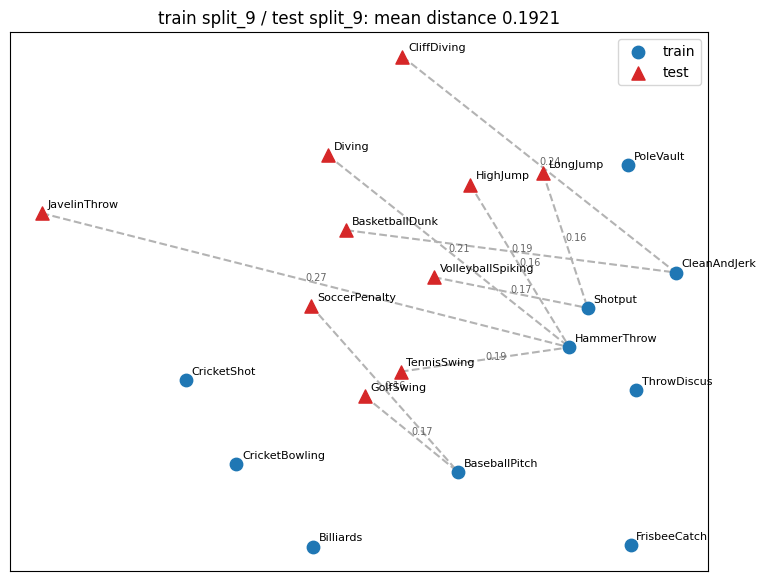

In [16]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.manifold import MDS
from make_far_splits import THUMOS_CLASSES as names, clip_text_embeddings

emb = clip_text_embeddings(names, "openai/clip-vit-base-patch16", "{}")
dist = np.clip(1 - emb @ emb.T, 0, None)  # cosine distance
xy = MDS(2, dissimilarity="precomputed", random_state=0).fit_transform(dist)

def plot_split(train_k, root="splits/train_50_test_50_far/THUMOS14"):
    load = lambda sub, k: [names.index(l.strip()) for l in open(f"{root}/{sub}/split_{k}.list") if l.strip()]
    train, test = load("train", train_k), load("test", train_k)
    nearest = [train[dist[t, train].argmin()] for t in test]
    d = np.array([dist[t, n] for t, n in zip(test, nearest)])
    print(f"mean distance (test -> nearest train): {d.mean():.4f}")

    plt.figure(figsize=(9, 7))
    for t, n, di in zip(test, nearest, d):  # dashed line: test class -> nearest train class
        plt.plot(*zip(xy[t], xy[n]), "--", c="0.7", zorder=0)
        plt.text(*(xy[t] + xy[n]) / 2, f"{di:.2f}", fontsize=7, color="0.4")
    plt.scatter(*xy[train].T, c="tab:blue", s=80, label="train")
    plt.scatter(*xy[test].T, c="tab:red", marker="^", s=90, label="test")
    for i, n in enumerate(names):
        plt.annotate(n, xy[i], xytext=(4, 4), textcoords="offset points", fontsize=8)
    plt.legend(); plt.xticks([]); plt.yticks([])
    plt.title(f"train split_{train_k} / test split_{train_k}: mean distance {d.mean():.4f}")
    plt.show()

plot_split(9)

mean distance (test -> nearest train): 0.1500


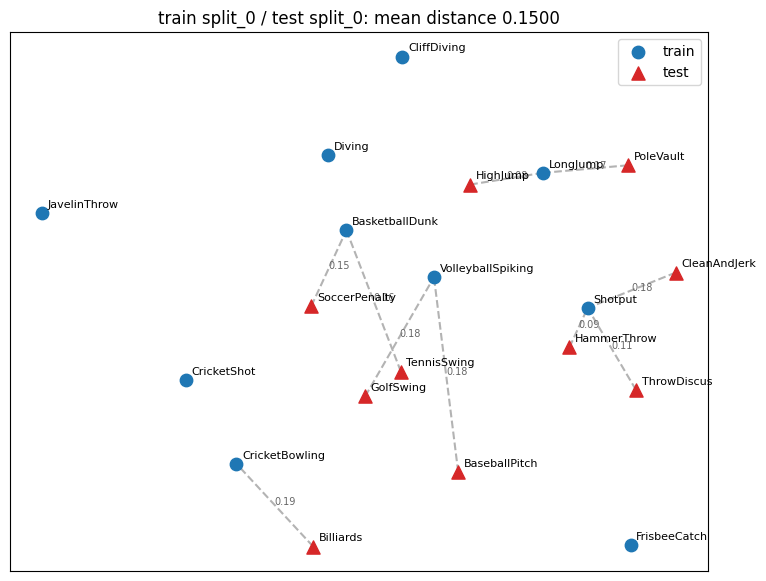

In [15]:
plot_split(0, root="splits/train_50_test_50/THUMOS14")